In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR: Path = Path("Banking_CLV_Data_20000")
OUT_DIR: Path = Path("output")
OUT_DIR.mkdir(exist_ok=True)

PERIOD_START: str = "2025-10-01"
PERIOD_END: str = "2026-09-30"
D_BASE: float = 0.10  #?: lãi suất chiết khấu gốc
UPLIFT: float = 0.03  #?: chiến dịch tăng retention thêm 3 điểm %
OFFER_COST: int = 100_000  #?: chi phí 1 ưu đãi (VND), trả ngay
BUDGET: int = 10_000_000
MAX_OFFERS: int = min(100, BUDGET // OFFER_COST)  #?: tối đa 100 khách và không vượt ngân sách
MONEY_COLS: list[str] = ["fee_revenue_vnd", "net_interest_income_vnd", "servicing_cost_vnd", "expected_credit_loss_vnd"]
NUM_COLS: list[str] = MONEY_COLS + ["annual_retention_rate"]

## 1. Chuẩn bị dữ liệu

### 1.1 Đọc dữ liệu

In [2]:
customers: pd.DataFrame = pd.read_csv(DATA_DIR / "customers.csv", dtype=str)  #?: đọc customer_id dạng text để giữ chữ C
econ_raw: pd.DataFrame = pd.read_csv(DATA_DIR / "customer_economics.csv", dtype=str)
print("Roster:", customers.shape)
print("Economics thô:", econ_raw.shape)
customers.head()

Roster: (20000, 5)
Economics thô: (20400, 8)


,customer_id,open_date,city,age_band,onboarding_channel
0,C00001,2020-04-02,Ho Chi Minh City,55+,Branch
1,C00002,2021-07-12,Can Tho,45-54,Branch
2,C00003,2020-01-28,Hai Phong,45-54,Branch
3,C00004,2021-05-16,Da Nang,25-34,Website
4,C00005,2016-11-28,Da Nang,25-34,Branch


### 1.2 Profile dữ liệu: thiếu, trùng, key, ngày, khoảng giá trị

In [3]:
print("Giá trị thiếu - customers")
print(customers.isna().sum())
print()
print("Giá trị thiếu - economics")
print(econ_raw.isna().sum())

Giá trị thiếu - customers
customer_id           0
open_date             0
city                  0
age_band              0
onboarding_channel    0
dtype: int64

Giá trị thiếu - economics
customer_id                   0
period_start                  0
period_end                    0
fee_revenue_vnd             100
net_interest_income_vnd       0
servicing_cost_vnd            0
expected_credit_loss_vnd    100
annual_retention_rate       100
dtype: int64


In [4]:
#?: kiểm tra customer_id của roster
print("customer_id roster bị trùng:", customers["customer_id"].duplicated().sum())
print("customer_id roster đúng dạng C + số:", customers["customer_id"].str.match(r"^C\d+$").all())

#?: kiểm tra ngày mở tài khoản
open_dates: pd.Series = pd.to_datetime(customers["open_date"], errors="coerce")
print("open_date không đọc được:", open_dates.isna().sum())
print("open_date nhỏ nhất / lớn nhất:", open_dates.min().date(), "/", open_dates.max().date())
print("Số khách mở sau 2025-10-01:", (open_dates > PERIOD_START).sum())

customer_id roster bị trùng: 0
customer_id roster đúng dạng C + số: True
open_date không đọc được: 0
open_date nhỏ nhất / lớn nhất: 2016-01-01 / 2025-10-01
Số khách mở sau 2025-10-01: 0


In [5]:
#?: kiểm tra key và kỳ của bảng economics
print("Dòng trùng hoàn toàn:", econ_raw.duplicated().sum())
print("Dòng trùng customer_id:", econ_raw["customer_id"].duplicated().sum())
print("ID không có trong roster:", (~econ_raw["customer_id"].isin(customers["customer_id"])).sum())
print("Khách roster không có dòng economics:", (~customers["customer_id"].isin(econ_raw["customer_id"])).sum())
print()
print(econ_raw["period_start"].value_counts(dropna=False))
print(econ_raw["period_end"].value_counts(dropna=False))

Dòng trùng hoàn toàn: 300
Dòng trùng customer_id: 300
ID không có trong roster: 100
Khách roster không có dòng economics: 0

period_start
2025-10-01    20400
Name: count, dtype: int64
period_end
2026-09-30    20300
2026-08-31      100
Name: count, dtype: int64


In [6]:
#?: đổi các cột số sang dạng số, giá trị lỗi sẽ thành NaN
econ_num: pd.DataFrame = econ_raw.copy()
for col in NUM_COLS:
    econ_num[col] = pd.to_numeric(econ_raw[col], errors="coerce")
    n_bad: int = int(econ_num[col].isna().sum() - econ_raw[col].isna().sum())
    print(col, "- không đọc được thành số:", n_bad)

econ_num[NUM_COLS].describe().round(3)

fee_revenue_vnd - không đọc được thành số: 0
net_interest_income_vnd - không đọc được thành số: 0
servicing_cost_vnd - không đọc được thành số: 0
expected_credit_loss_vnd - không đọc được thành số: 0
annual_retention_rate - không đọc được thành số: 0


,fee_revenue_vnd,net_interest_income_vnd,servicing_cost_vnd,expected_credit_loss_vnd,annual_retention_rate
count,20300.000,20400.000,20400.000,20300.000,20300.000
mean,1034358.177,3516555.931,1000462.157,915332.660,0.742
std,788306.982,2487409.640,484883.152,607046.306,0.155
min,0.000,0.000,-898000.000,0.000,-0.050
25%,287000.000,1103500.000,613000.000,388000.000,0.621
50%,951000.000,3384000.000,1007000.000,908000.000,0.743
75%,1731000.000,5705000.000,1415000.000,1443250.000,0.869
max,2500000.000,8000000.000,1900000.000,2000000.000,1.080


In [7]:
#?: đếm số dòng vi phạm từng quy tắc (một dòng có thể vi phạm nhiều quy tắc)
r_col: pd.Series = econ_num["annual_retention_rate"]
issue_counts: dict[str, int] = {
    "fee_revenue thiếu": int(econ_num["fee_revenue_vnd"].isna().sum()),
    "net_interest_income thiếu": int(econ_num["net_interest_income_vnd"].isna().sum()),
    "servicing_cost thiếu": int(econ_num["servicing_cost_vnd"].isna().sum()),
    "expected_credit_loss thiếu": int(econ_num["expected_credit_loss_vnd"].isna().sum()),
    "retention thiếu": int(r_col.isna().sum()),
    "có thành phần tài chính < 0": int((econ_num[MONEY_COLS] < 0).any(axis=1).sum()),
    "retention < 0": int((r_col < 0).sum()),
    "retention > 1": int((r_col > 1).sum()),
    "period_end khác 2026-09-30": int((econ_num["period_end"] != PERIOD_END).sum()),
    "period_start khác 2025-10-01": int((econ_num["period_start"] != PERIOD_START).sum()),
}
pd.Series(issue_counts, name="số dòng").to_frame()

,số dòng
fee_revenue thiếu,100
net_interest_income thiếu,0
servicing_cost thiếu,0
expected_credit_loss thiếu,100
retention thiếu,100
có thành phần tài chính < 0,100
retention < 0,100
retention > 1,100
period_end khác 2026-09-30,100
period_start khác 2025-10-01,0


### 1.3 Làm sạch

Các quyết định:
- **Dòng trùng hoàn toàn**: giữ 1 dòng, bỏ phần còn lại.
- **Dòng cùng customer_id nhưng số liệu khác nhau (mâu thuẫn)**: không biết dòng nào đúng nên bỏ hết các dòng đó và gắn cờ `conflicting_rows`. (Dữ liệu này không có trường hợp nào.)
- **ID không có trong roster**: loại khỏi phân tích, không thêm vào roster.
- **Kỳ không đủ năm** (period_end khác 2026-09-30): không dùng được, vì số liệu chưa đủ 12 tháng. Không nhân lên cho đủ năm.
- **Thiếu giá trị**: không điền 0 và không điền trung bình. Khách đó có CLV trống và được gắn cờ.
- **Giá trị không hợp lệ** (thành phần tài chính âm, retention ngoài [0, 1]): có thể là lỗi nhập liệu nhưng không biết giá trị đúng. Không tự sửa, CLV để trống.
- **Giá trị 0 thật** và **contribution âm** (do chi phí lớn hơn thu nhập) thì giữ nguyên.

In [8]:
n_raw: int = len(econ_raw)

#?: bước 1 - bỏ dòng trùng hoàn toàn (so sánh trên dữ liệu chữ gốc)
dup_mask: pd.Series = econ_raw.duplicated(keep="first")
n_exact_dup: int = int(dup_mask.sum())
econ: pd.DataFrame = econ_num[~dup_mask].copy()

#?: bước 2 - tìm customer_id còn bị lặp sau khi bỏ trùng hoàn toàn (tức là mâu thuẫn)
conflict_mask: pd.Series = econ["customer_id"].duplicated(keep=False)
conflict_ids: set[str] = set(econ.loc[conflict_mask, "customer_id"])
n_conflict_rows: int = int(conflict_mask.sum())
econ = econ[~conflict_mask]

#?: bước 3 - bỏ ID không có trong roster
unmatched_mask: pd.Series = ~econ["customer_id"].isin(customers["customer_id"])
n_unmatched: int = int(unmatched_mask.sum())
unmatched_ids: list[str] = econ.loc[unmatched_mask, "customer_id"].tolist()
econ = econ[~unmatched_mask]

n_clean_rows: int = len(econ)
print("Dòng thô:", n_raw)
print("Bỏ dòng trùng hoàn toàn:", n_exact_dup)
print("Bỏ dòng mâu thuẫn:", n_conflict_rows)
print("Bỏ ID không khớp roster:", n_unmatched, "- ví dụ:", unmatched_ids[:3])
print("Dòng sau làm sạch:", n_clean_rows)

Dòng thô: 20400
Bỏ dòng trùng hoàn toàn: 300
Bỏ dòng mâu thuẫn: 0
Bỏ ID không khớp roster: 100 - ví dụ: ['C90015', 'C90096', 'C90085']
Dòng sau làm sạch: 20000


In [9]:
#?: ghép vào roster bằng customer_id, validate đảm bảo mỗi khách tối đa 1 dòng
df: pd.DataFrame = customers.merge(econ, on="customer_id", how="left", validate="one_to_one")
print("Số khách sau khi ghép:", len(df))
assert len(df) == len(customers) == 20000

#?: gắn quality_status, điều kiện đứng trước được ưu tiên (mỗi khách chỉ có 1 trạng thái)
has_row: pd.Series = df["period_start"].notna()
partial: pd.Series = has_row & ((df["period_start"] != PERIOD_START) | (df["period_end"] != PERIOD_END))
missing: pd.Series = has_row & df[NUM_COLS].isna().any(axis=1)
bad_money: pd.Series = (df[MONEY_COLS] < 0).any(axis=1)
bad_r: pd.Series = (df["annual_retention_rate"] < 0) | (df["annual_retention_rate"] > 1)
invalid: pd.Series = has_row & (bad_money | bad_r)

conditions: list[pd.Series] = [
    df["customer_id"].isin(conflict_ids),
    ~has_row,
    partial,
    missing,
    invalid,
]
labels: list[str] = ["conflicting_rows", "no_economics_row", "partial_period", "missing_input", "invalid_input"]
df["quality_status"] = np.select(conditions, labels, default="ok")
df["quality_status"].value_counts()

Số khách sau khi ghép: 20000


quality_status
ok                19300
missing_input       300
invalid_input       300
partial_period      100
Name: count, dtype: int64

In [10]:
#?: bảng đối chiếu: dòng thô -> dòng sạch -> số khách cuối cùng
status_counts: pd.Series = df["quality_status"].value_counts()
n_valid: int = int(status_counts.get("ok", 0))
n_excluded: int = len(df) - n_valid

recon: pd.DataFrame = pd.DataFrame({
    "bước": [
        "Dòng economics thô",
        "- Dòng trùng hoàn toàn bị bỏ",
        "- Dòng mâu thuẫn bị bỏ",
        "- Dòng ID không có trong roster bị bỏ",
        "= Dòng economics sạch",
        "+ Khách roster không có dòng economics",
        "= Số khách trong file cuối (roster)",
        "  trong đó: tính được CLV (ok)",
        "  trong đó: CLV trống (Unscored)",
    ],
    "số lượng": [n_raw, n_exact_dup, n_conflict_rows, n_unmatched, n_clean_rows,
                 int(status_counts.get("no_economics_row", 0)), len(df), n_valid, n_excluded],
})
print(recon.to_string(index=False))

print()
print("Loại khỏi CLV theo lý do (mỗi khách chỉ đếm 1 lý do):")
print(status_counts[status_counts.index != "ok"])

assert n_raw - n_exact_dup - n_conflict_rows - n_unmatched == n_clean_rows
assert n_clean_rows + status_counts.get("no_economics_row", 0) + len(conflict_ids) == len(df)
assert n_valid + n_excluded == len(df)

                                  bước  số lượng
                    Dòng economics thô     20400
          - Dòng trùng hoàn toàn bị bỏ       300
                - Dòng mâu thuẫn bị bỏ         0
 - Dòng ID không có trong roster bị bỏ       100
                 = Dòng economics sạch     20000
+ Khách roster không có dòng economics         0
   = Số khách trong file cuối (roster)     20000
          trong đó: tính được CLV (ok)     19300
        trong đó: CLV trống (Unscored)       700

Loại khỏi CLV theo lý do (mỗi khách chỉ đếm 1 lý do):
quality_status
missing_input     300
invalid_input     300
partial_period    100
Name: count, dtype: int64


In [11]:
#?: lưu bảng đối chiếu và danh sách ID lạ để làm bằng chứng
recon.to_csv(OUT_DIR / "cleaning_log.csv", index=False)
pd.DataFrame({"unmatched_customer_id": unmatched_ids}).to_csv(OUT_DIR / "unmatched_ids.csv", index=False)

**Nhận xét Task 1**
- 20.400 dòng thô, trừ 300 dòng trùng hoàn toàn và 100 dòng có ID lạ (C9xxxx, không có trong roster) còn 20.000 dòng sạch, đúng bằng số khách trong roster.
- Không có dòng mâu thuẫn (cùng ID nhưng số khác nhau).
- 19.300 khách tính được CLV. 700 khách có CLV trống: 300 thiếu dữ liệu (100 thiếu fee, 100 thiếu ECL, 100 thiếu retention), 300 dữ liệu không hợp lệ (100 servicing_cost âm, 100 retention < 0, 100 retention > 1) và 100 kỳ chỉ đến 2026-08-31.
- Các lỗi này không chồng lên nhau, nên mỗi khách chỉ có 1 lý do.

## Task 2. Tính CLV

Công thức: m = fee + net_interest − servicing_cost − expected_credit_loss

CLV = m·r/(1+d) + m·r²/(1+d)² + m·r³/(1+d)³

Chỉ khách có `quality_status == "ok"` mới được tính CLV. Khách còn lại để CLV là NaN (khác với 0).

In [12]:
#@ Tính CLV 3 năm từ contribution m, retention r và lãi suất chiết khấu d
def clv_3yr(m: pd.Series, r: pd.Series, d: float) -> pd.Series:
    total: pd.Series = m * 0.0  #?: bắt đầu từ 0, cùng index với m
    for t in [1, 2, 3]:
        total = total + m * (r ** t) / ((1 + d) ** t)  #?: năm t: m*r^t chia (1+d)^t
    return total

In [13]:
#?: tính m cho mọi khách có đủ 4 thành phần hợp lệ, r cho khách có r hợp lệ
df["annual_contribution_vnd"] = (df["fee_revenue_vnd"] + df["net_interest_income_vnd"]
                                 - df["servicing_cost_vnd"] - df["expected_credit_loss_vnd"])
is_ok: pd.Series = df["quality_status"] == "ok"

#! m và r chỉ được hiển thị khi dòng hợp lệ, nếu không sẽ lẫn giá trị lỗi (vd r = -0.05) vào file kết quả
df.loc[~is_ok, "annual_contribution_vnd"] = np.nan
df["annual_retention_rate"] = df["annual_retention_rate"].where(is_ok)

df["clv_3yr_vnd"] = clv_3yr(df["annual_contribution_vnd"], df["annual_retention_rate"], D_BASE)
print("CLV tính được:", df["clv_3yr_vnd"].notna().sum())
print("CLV trống:", df["clv_3yr_vnd"].isna().sum())
print("Số khách CLV âm:", (df["clv_3yr_vnd"] < 0).sum(), "| CLV = 0:", (df["clv_3yr_vnd"] == 0).sum())
df["clv_3yr_vnd"].describe().round(0)

CLV tính được: 19300
CLV trống: 700
Số khách CLV âm: 4386 | CLV = 0: 60


count       19300.0
mean      3896670.0
std       4784631.0
min      -8167054.0
25%        330339.0
50%       3570960.0
75%       6884432.0
max      22192845.0
Name: clv_3yr_vnd, dtype: float64

### Giá trị từng năm

In [14]:
#?: expected contribution năm t = m * r^t, rồi chiết khấu chia (1.1)^t
by_year: pd.DataFrame = df.loc[is_ok, ["customer_id", "annual_contribution_vnd", "annual_retention_rate"]].copy()
for t in [1, 2, 3]:
    by_year[f"expected_y{t}"] = by_year["annual_contribution_vnd"] * by_year["annual_retention_rate"] ** t
    by_year[f"pv_y{t}"] = by_year[f"expected_y{t}"] / (1 + D_BASE) ** t
by_year["clv_3yr_vnd"] = by_year[["pv_y1", "pv_y2", "pv_y3"]].sum(axis=1)

#?: kiểm tra tổng 3 năm khớp với hàm clv_3yr
assert np.allclose(by_year["clv_3yr_vnd"], df.loc[is_ok, "clv_3yr_vnd"])
by_year.to_csv(OUT_DIR / "clv_by_year.csv", index=False)
by_year.head()

,customer_id,annual_contribution_vnd,annual_retention_rate,expected_y1,pv_y1,expected_y2,pv_y2,expected_y3,pv_y3,clv_3yr_vnd
0,C00001,2588000.0,1.000,2588000.0,2.352727e+06,2588000.000,2.138843e+06,2.588000e+06,1.944403e+06,6.435973e+06
1,C00002,1139000.0,0.000,0.0,0.000000e+00,0.000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
2,C00003,0.0,0.910,0.0,0.000000e+00,0.000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
3,C00004,0.0,0.979,0.0,0.000000e+00,0.000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
4,C00005,-65000.0,0.987,-64155.0,-5.832273e+04,-63320.985,-5.233139e+04,-6.249781e+04,-4.695553e+04,-1.576097e+05


### Kiểm tra tay 2 khách hàng

In [15]:
#@ Tính tay CLV bằng vòng lặp từng năm rồi so với kết quả của hàm
def check_by_hand(cid: str) -> None:
    row: pd.Series = df[df["customer_id"] == cid].iloc[0]
    fee: float = row["fee_revenue_vnd"]
    nii: float = row["net_interest_income_vnd"]
    serv: float = row["servicing_cost_vnd"]
    ecl: float = row["expected_credit_loss_vnd"]
    r: float = row["annual_retention_rate"]
    m: float = fee + nii - serv - ecl
    print(f"Khách {cid}: m = {fee:,.0f} + {nii:,.0f} - {serv:,.0f} - {ecl:,.0f} = {m:,.0f}, r = {r}")
    total: float = 0.0
    for t in [1, 2, 3]:
        expected: float = m * r ** t
        pv: float = expected / 1.10 ** t
        total += pv
        print(f"  Năm {t}: m*r^{t} = {expected:,.0f} -> chiết khấu = {pv:,.0f}")
    print(f"  CLV tay = {total:,.0f} | CLV code = {row['clv_3yr_vnd']:,.0f}")
    assert abs(total - row["clv_3yr_vnd"]) < 1e-6

first_valid: str = df.loc[is_ok, "customer_id"].iloc[0]
first_negative: str = df.loc[df["clv_3yr_vnd"] < 0, "customer_id"].iloc[0]  #?: chọn thêm 1 khách CLV âm để thấy CLV âm được giữ lại
check_by_hand(first_valid)
check_by_hand(first_negative)

Khách C00001: m = 2,253,000 + 2,056,000 - 291,000 - 1,430,000 = 2,588,000, r = 1.0
  Năm 1: m*r^1 = 2,588,000 -> chiết khấu = 2,352,727
  Năm 2: m*r^2 = 2,588,000 -> chiết khấu = 2,138,843
  Năm 3: m*r^3 = 2,588,000 -> chiết khấu = 1,944,403
  CLV tay = 6,435,973 | CLV code = 6,435,973
Khách C00005: m = 1,971,000 + 1,095,000 - 1,369,000 - 1,762,000 = -65,000, r = 0.987
  Năm 1: m*r^1 = -64,155 -> chiết khấu = -58,323
  Năm 2: m*r^2 = -63,321 -> chiết khấu = -52,331
  Năm 3: m*r^3 = -62,498 -> chiết khấu = -46,956
  CLV tay = -157,610 | CLV code = -157,610


## Task 3. Xếp hạng và phân khúc

**Xếp hạng**: chỉ xếp khách có CLV hợp lệ, từ cao xuống thấp. Nếu CLV bằng nhau thì khách có `customer_id` nhỏ hơn đứng trước, nên mỗi khách có một hạng riêng (1, 2, 3, ...). Khách CLV trống không có hạng.

In [16]:
valid_sorted: pd.DataFrame = df[is_ok].sort_values(["clv_3yr_vnd", "customer_id"], ascending=[False, True])
valid_sorted["clv_rank"] = np.arange(1, len(valid_sorted) + 1)
df = df.merge(valid_sorted[["customer_id", "clv_rank"]], on="customer_id", how="left")
df["clv_rank"] = df["clv_rank"].astype("Int64")  #?: Int64 cho phép giá trị trống
df[df["clv_rank"].notna()].sort_values("clv_rank").head(10)[["customer_id", "annual_contribution_vnd", "annual_retention_rate", "clv_3yr_vnd", "clv_rank"]]

,customer_id,annual_contribution_vnd,annual_retention_rate,clv_3yr_vnd,clv_rank
19069,C19070,9389000.0,0.974,2.219285e+07,1
5796,C05797,9650000.0,0.958,2.209813e+07,2
13023,C13024,9205000.0,0.974,2.175792e+07,3
6324,C06325,9161000.0,0.976,2.173936e+07,4
1330,C01331,9028000.0,0.980,2.159281e+07,5
19489,C19490,8931000.0,0.983,2.148680e+07,6
352,C00353,8734000.0,0.990,2.130223e+07,7
11193,C11194,8885000.0,0.972,2.091888e+07,8
1660,C01661,9953000.0,0.910,2.068056e+07,9
6260,C06261,8489000.0,0.987,2.058382e+07,10


**Quy tắc phân khúc** (mỗi khách rơi vào đúng 1 nhóm, kiểm tra từ trên xuống):

| # | Segment | Điều kiện |
|---|---|---|
| 1 | Unscored | CLV trống |
| 2 | Negative Value | CLV < 0 |
| 3 | Zero Value | CLV = 0 |
| 4 | High Value / Stable | CLV > 0, CLV ≥ P75 của các CLV dương, r ≥ 0.75 |
| 5 | High Value / At Risk | CLV > 0, CLV ≥ P75 của các CLV dương, r < 0.75 |
| 6 | Low Positive Value | CLV > 0 còn lại |

Lý do chọn ngưỡng:
- **P75 của CLV dương**: lấy 25% khách giá trị cao nhất trong nhóm CLV dương làm "High Value", để nhóm này đủ nhỏ cho CRM tập trung.
- **r = 0.75**: gần với trung vị của retention (khoảng 0.74), là con số tròn dễ giải thích. Trên 0.75 coi là ổn định, dưới là có nguy cơ rời bỏ.

In [17]:
#@ Gán segment cho một khách theo quy tắc ở trên
def assign_segment(clv: float, r: float, high_cut: float, r_cut: float) -> str:
    if pd.isna(clv):
        return "Unscored"
    if clv < 0:
        return "Negative Value"
    if clv == 0:
        return "Zero Value"
    if clv >= high_cut:
        return "High Value / Stable" if r >= r_cut else "High Value / At Risk"
    return "Low Positive Value"

positive_clv: pd.Series = df.loc[df["clv_3yr_vnd"] > 0, "clv_3yr_vnd"]
HIGH_CUT: float = float(positive_clv.quantile(0.75))
R_CUT: float = 0.75
print(f"Ngưỡng High Value (P75 CLV dương): {HIGH_CUT:,.0f} VND")

df["segment"] = [assign_segment(c, r, HIGH_CUT, R_CUT)
                 for c, r in zip(df["clv_3yr_vnd"], df["annual_retention_rate"])]
assert df["segment"].notna().all()  #?: ai cũng có đúng 1 segment

Ngưỡng High Value (P75 CLV dương): 7,963,869 VND


In [18]:
SEGMENT_ORDER: list[str] = ["High Value / Stable", "High Value / At Risk", "Low Positive Value",
                            "Zero Value", "Negative Value", "Unscored"]
seg_table: pd.DataFrame = df.groupby("segment").agg(
    so_khach=("customer_id", "count"),
    tong_clv=("clv_3yr_vnd", "sum"),
    clv_trung_vi=("clv_3yr_vnd", "median"),
).reindex(SEGMENT_ORDER)
seg_table["so_khach"] = seg_table["so_khach"].fillna(0).astype(int)
seg_table["tong_clv"] = seg_table["tong_clv"].fillna(0)  #?: Unscored không có CLV, tổng = 0 chỉ để hiển thị
assert seg_table["so_khach"].sum() == len(df)
seg_table.round(0)

,so_khach,tong_clv,clv_trung_vi
segment,,,
High Value / Stable,3068,3.557145e+10,11086708.0
High Value / At Risk,646,5.971021e+09,8969485.0
Low Positive Value,11140,4.279800e+10,3806428.0
Zero Value,60,0.000000e+00,0.0
Negative Value,4386,-9.134732e+09,-1865873.0
Unscored,700,0.000000e+00,NaN


**Ý nghĩa từng segment**
- **High Value / Stable**: giá trị cao, ít rời bỏ. Giữ quan hệ tốt, chăm sóc thường xuyên, bán thêm sản phẩm phù hợp.
- **High Value / At Risk**: giá trị cao nhưng retention thấp hơn 0.75. Ưu tiên liên hệ sớm để giữ chân.
- **Low Positive Value**: có lãi nhưng ít. Dùng kênh số, chi phí thấp, tìm cách tăng sử dụng dịch vụ.
- **Zero Value**: contribution bằng 0. Theo dõi, chưa cần chi thêm.
- **Negative Value**: chi phí lớn hơn thu nhập. Xem lại chi phí phục vụ và rủi ro tín dụng, không dùng CLV một mình để hạn chế dịch vụ.
- **Unscored**: chưa có CLV vì dữ liệu lỗi hoặc thiếu. Cần sửa dữ liệu trước khi quyết định.

## Task 4. Insight và chiến dịch

### 4.1 Ba biểu đồ

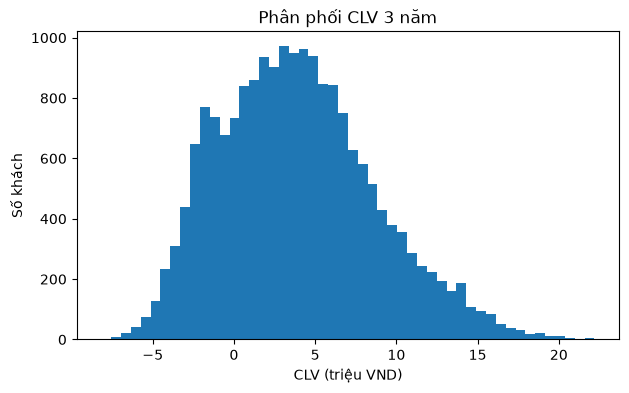

In [19]:
#?: biểu đồ 1 - phân phối CLV (đơn vị triệu VND)
plt.figure(figsize=(7, 4))
plt.hist(df["clv_3yr_vnd"].dropna() / 1e6, bins=50)
plt.title("Phân phối CLV 3 năm")
plt.xlabel("CLV (triệu VND)")
plt.ylabel("Số khách")
plt.savefig(OUT_DIR / "chart1_clv_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

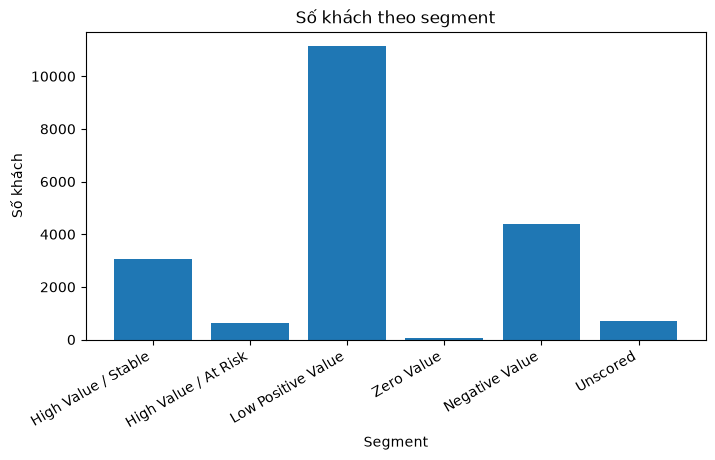

In [20]:
#?: biểu đồ 2 - số khách theo segment
plt.figure(figsize=(8, 4))
plt.bar(seg_table.index, seg_table["so_khach"])
plt.title("Số khách theo segment")
plt.xlabel("Segment")
plt.ylabel("Số khách")
plt.xticks(rotation=30, ha="right")
plt.savefig(OUT_DIR / "chart2_segment_counts.png", dpi=120, bbox_inches="tight")
plt.show()

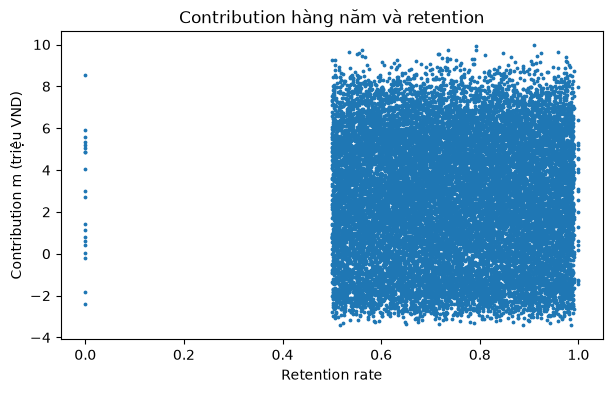

In [21]:
#?: biểu đồ 3 - contribution hàng năm và retention (mỗi chấm là 1 khách)
plt.figure(figsize=(7, 4))
plt.scatter(df["annual_retention_rate"], df["annual_contribution_vnd"] / 1e6, s=3)
plt.title("Contribution hàng năm và retention")
plt.xlabel("Retention rate")
plt.ylabel("Contribution m (triệu VND)")
plt.savefig(OUT_DIR / "chart3_contribution_vs_retention.png", dpi=120, bbox_inches="tight")
plt.show()

**Nhận xét biểu đồ**
- Biểu đồ 1: CLV trải rộng từ khoảng −8 đến 22 triệu VND, trung vị khoảng 3,6 triệu. Có 4.386 khách (khoảng 23%) CLV âm và đuôi dài bên phải.
- Biểu đồ 2: nhóm Low Positive Value đông nhất (11.140 khách). Nhóm High Value / At Risk nhỏ nhất trong các nhóm có giá trị (646 khách).
- Biểu đồ 3: retention nằm khoảng 0,5 đến 1 và contribution trải đều ở mọi mức retention, nên contribution cao không có nghĩa là retention cao. Có một ít khách có retention đúng bằng 0 (hợp lệ, giữ lại), CLV của họ bằng 0 dù contribution có thể dương.

### 4.2 Chọn khách cho chiến dịch

- r' = min(1, r + 0.03), giữ nguyên m
- Giá trị tăng thêm (`campaign_delta_vnd`) = CLV(r') − CLV(r) − 100.000
- Chỉ chọn khách có delta > 0, sắp xếp delta giảm dần, nếu bằng nhau thì `customer_id` nhỏ hơn trước, lấy tối đa 100 khách (100 × 100.000 = 10 triệu đúng bằng ngân sách).

In [22]:
#@ Tính CLV, CLV khi có chiến dịch và delta cho khách hợp lệ trong 1 kịch bản (d, shift)
def scenario_frame(valid: pd.DataFrame, d: float, shift: float) -> pd.DataFrame:
    r_s: pd.Series = (valid["annual_retention_rate"] + shift).clip(0, 1)  #?: dịch r rồi giới hạn trong [0, 1]
    r_c: pd.Series = (r_s + UPLIFT).clip(upper=1)  #?: r' = min(1, r + 0.03)
    out: pd.DataFrame = pd.DataFrame({"customer_id": valid["customer_id"]})
    out["clv"] = clv_3yr(valid["annual_contribution_vnd"], r_s, d)
    out["clv_campaign"] = clv_3yr(valid["annual_contribution_vnd"], r_c, d)
    out["delta"] = out["clv_campaign"] - out["clv"] - OFFER_COST
    return out

#@ Chọn tối đa MAX_OFFERS khách có delta > 0 lớn nhất, hòa thì customer_id nhỏ hơn trước
def select_campaign(frame: pd.DataFrame) -> pd.DataFrame:
    positive: pd.DataFrame = frame[frame["delta"] > 0]
    ordered: pd.DataFrame = positive.sort_values(["delta", "customer_id"], ascending=[False, True])
    return ordered.head(MAX_OFFERS)

valid_df: pd.DataFrame = df[is_ok]
base_frame: pd.DataFrame = scenario_frame(valid_df, D_BASE, 0.0)
base_sel: pd.DataFrame = select_campaign(base_frame)

n_sel: int = len(base_sel)
total_cost: int = n_sel * OFFER_COST
total_gain: float = float(base_sel["delta"].sum())
assert total_cost <= BUDGET
print("Số khách được chọn:", n_sel)
print(f"Chi phí: {total_cost:,.0f} VND")
print(f"Tổng lãi ròng (sau chi phí): {total_gain:,.0f} VND")
print("Số khách có delta > 0:", (base_frame["delta"] > 0).sum())

Số khách được chọn: 100
Chi phí: 10,000,000 VND
Tổng lãi ròng (sau chi phí): 101,998,033 VND
Số khách có delta > 0: 13076


In [23]:
#?: đưa delta và selected vào bảng chính
df = df.merge(base_frame[["customer_id", "delta"]].rename(columns={"delta": "campaign_delta_vnd"}), on="customer_id", how="left")
df["selected"] = df["customer_id"].isin(base_sel["customer_id"]).astype(int)

top10_campaign: pd.DataFrame = df[df["selected"] == 1].sort_values("campaign_delta_vnd", ascending=False).head(10)
top10_campaign[["customer_id", "annual_contribution_vnd", "annual_retention_rate", "clv_3yr_vnd", "clv_rank", "campaign_delta_vnd"]]

,customer_id,annual_contribution_vnd,annual_retention_rate,clv_3yr_vnd,clv_rank,campaign_delta_vnd
5796,C05797,9650000.0,0.958,2.209813e+07,2,1.246580e+06
1660,C01661,9953000.0,0.910,2.068056e+07,9,1.203858e+06
16706,C16707,9595000.0,0.924,2.051703e+07,12,1.180551e+06
19719,C19720,9438000.0,0.916,1.985381e+07,20,1.146307e+06
5146,C05147,8872000.0,0.958,2.031654e+07,15,1.138016e+06
10876,C10877,8919000.0,0.948,2.002001e+07,18,1.128476e+06
9250,C09251,9163000.0,0.922,1.951347e+07,27,1.119663e+06
18646,C18647,9116000.0,0.913,1.905870e+07,39,1.098992e+06
14694,C14695,9202000.0,0.903,1.884574e+07,45,1.094254e+06
17158,C17159,8513000.0,0.959,1.953329e+07,26,1.089464e+06


In [24]:
#?: danh sách đầy đủ 100 khách được chọn
selected_list: pd.DataFrame = df[df["selected"] == 1].sort_values("campaign_delta_vnd", ascending=False)
selected_list[["customer_id", "annual_contribution_vnd", "annual_retention_rate", "clv_3yr_vnd", "clv_rank", "segment", "campaign_delta_vnd"]].to_csv(OUT_DIR / "campaign_selected.csv", index=False)
print(selected_list["segment"].value_counts())
print("Retention trung bình của nhóm được chọn:", round(selected_list["annual_retention_rate"].mean(), 3))
print("Retention trung bình của toàn bộ khách hợp lệ:", round(valid_df["annual_retention_rate"].mean(), 3))

segment
High Value / Stable    100
Name: count, dtype: int64
Retention trung bình của nhóm được chọn: 0.926
Retention trung bình của toàn bộ khách hợp lệ: 0.744


In [25]:
#?: so sánh nhóm được chọn với top 100 theo CLV
top100_clv: set[str] = set(df.loc[df["clv_rank"] <= 100, "customer_id"])
overlap: int = len(top100_clv & set(base_sel["customer_id"]))
print("Số khách vừa thuộc top 100 CLV vừa được chọn:", overlap)

Số khách vừa thuộc top 100 CLV vừa được chọn: 66


**Kết quả chiến dịch**
- Chọn đủ 100 khách, chi phí 10.000.000 VND (đúng bằng ngân sách), tổng lãi ròng khoảng **102,0 triệu VND**.
- Có 13.076 khách có delta > 0, nhưng ngân sách chỉ đủ cho 100 khách nên chọn 100 khách có delta lớn nhất.
- Cả 100 khách đều thuộc High Value / Stable, retention trung bình 0,926 (so với 0,744 của toàn bộ khách).

**Vì sao khác với danh sách CLV cao nhất?** Chỉ 66 trong 100 khách CLV cao nhất được chọn.
- Delta là phần CLV tăng thêm khi r tăng 3 điểm. Khách có r gần 1 bị "chặn trên" (r' tối đa là 1) nên tăng thêm ít, dù CLV rất cao. Ví dụ khách hạng 1 (r = 0,974) không nằm trong top 10 delta.
- Khách có m lớn và r khoảng 0,90 - 0,96 còn nhiều chỗ để tăng, nên delta lớn nhất.
- Vì vậy phải ưu tiên theo delta, không theo CLV.

**KPI đề xuất**: tỷ lệ khách còn hoạt động sau 12 tháng của nhóm được tặng ưu đãi so với nhóm đối chứng (không tặng), mục tiêu cao hơn ít nhất 3 điểm %. Có thể theo dõi thêm contribution thực tế trên mỗi VND chi cho chiến dịch.

## Task 5. Phân tích độ nhạy

Lưới 3 × 3: d ∈ {5%, 10%, 15%} và dịch r ∈ {−5, 0, +5 điểm %}. Mỗi kịch bản tính lại CLV, chọn lại khách chiến dịch (cùng quy tắc delta > 0, tối đa 100, hòa thì ID nhỏ hơn trước), rồi so với kịch bản gốc (d = 10%, shift = 0).

In [26]:
D_LIST: list[float] = [0.05, 0.10, 0.15]
SHIFT_LIST: list[float] = [-0.05, 0.0, 0.05]

#@ Lấy 10 khách có CLV cao nhất của một kịch bản (hòa thì ID nhỏ hơn trước)
def top10_ids(frame: pd.DataFrame) -> list[str]:
    ordered: pd.DataFrame = frame.sort_values(["clv", "customer_id"], ascending=[False, True])
    return ordered["customer_id"].head(10).tolist()

base_top10: list[str] = top10_ids(base_frame)
base_selected: set[str] = set(base_sel["customer_id"])

rows: list[dict] = []
for d in D_LIST:
    for shift in SHIFT_LIST:
        frame: pd.DataFrame = scenario_frame(valid_df, d, shift)
        sel: pd.DataFrame = select_campaign(frame)
        sel_ids: set[str] = set(sel["customer_id"])
        same_sel: int = len(sel_ids & base_selected)
        rows.append({
            "d": d,
            "shift": shift,
            "tong_clv_vnd": frame["clv"].sum(),
            "so_khach_chon": len(sel),
            "chi_phi_vnd": len(sel) * OFFER_COST,
            "lai_rong_vnd": sel["delta"].sum(),
            "top10_giong_goc": len(set(top10_ids(frame)) & set(base_top10)),
            "chon_giong_goc": same_sel,
            "chon_khac_goc": len(sel_ids) - same_sel,
        })

scenarios: pd.DataFrame = pd.DataFrame(rows)
scenarios.to_csv(OUT_DIR / "scenario_summary.csv", index=False)
scenarios.round({"tong_clv_vnd": 0, "lai_rong_vnd": 0})

,d,shift,tong_clv_vnd,so_khach_chon,chi_phi_vnd,lai_rong_vnd,top10_giong_goc,chon_giong_goc,chon_khac_goc
0,0.05,-0.05,7.254141e+10,100,10000000,110424907.0,9,70,30
1,0.05,0.00,8.173838e+10,100,10000000,114394179.0,10,100,0
2,0.05,0.05,9.118663e+10,100,10000000,115272590.0,8,42,58
3,0.10,-0.05,6.686660e+10,100,10000000,98518840.0,10,70,30
4,0.10,0.00,7.520574e+10,100,10000000,101998033.0,10,100,0
5,0.10,0.05,8.375973e+10,100,10000000,102801169.0,8,42,58
6,0.15,-0.05,6.193677e+10,100,10000000,88373083.0,10,71,29
7,0.15,0.00,6.954080e+10,100,10000000,91430288.0,10,100,0
8,0.15,0.05,7.732934e+10,100,10000000,92170105.0,8,42,58


In [27]:
#?: kiểm tra kịch bản gốc trong bảng khớp với kết quả ở Task 4
base_row: pd.Series = scenarios[(scenarios["d"] == 0.10) & (scenarios["shift"] == 0.0)].iloc[0]
assert abs(base_row["lai_rong_vnd"] - total_gain) < 1e-6
assert base_row["chon_giong_goc"] == n_sel
print("Top 10 CLV kịch bản gốc:", base_top10)

Top 10 CLV kịch bản gốc: ['C19070', 'C05797', 'C13024', 'C06325', 'C01331', 'C19490', 'C00353', 'C11194', 'C01661', 'C06261']


**Nhận xét bảng 9 kịch bản**
- Tổng CLV: thấp nhất 61,9 tỷ (d = 15%, r − 5 điểm), cao nhất 91,2 tỷ (d = 5%, r + 5 điểm). Kịch bản gốc là 75,2 tỷ VND.
- Lãi ròng chiến dịch dao động từ 88,4 đến 115,3 triệu VND, quanh mức gốc 102,0 triệu.
- Chiết khấu thấp hơn hoặc retention cao hơn đều làm CLV tăng.

**Độ ổn định**
- **Top 10 CLV**: giống kịch bản gốc 8 - 10 khách trong cả 9 kịch bản (8 khách khi r + 5 điểm, 9 hoặc 10 ở các kịch bản còn lại).
- **Danh sách chọn chiến dịch**: khi chỉ đổi d (shift = 0) danh sách giống hệt gốc (100/100). Khi r thay đổi ±5 điểm thì chỉ còn 70 - 71 (r − 5) hoặc 42 (r + 5) khách giống gốc, tức đổi 29 - 58 khách.
- Kết luận: danh sách khách CLV cao khá ổn định, nhưng danh sách chiến dịch phụ thuộc nhiều vào giả định retention. Nên dùng retention đã được kiểm chứng.

**Hạn chế**
1. **Contribution không đổi và attrition vĩnh viễn**: thực tế contribution thay đổi theo năm, khách có thể quay lại hoặc dùng thêm sản phẩm.
2. **Chỉ 3 năm, không có giá trị cuối kỳ**: khách ổn định (r cao) còn giá trị sau năm 3 nhưng bị bỏ qua, nên CLV thấp hơn thực tế.
3. **Uplift 3 điểm chỉ là giả định**: chưa có bằng chứng ưu đãi thật sự tăng retention, và mức tăng có thể khác nhau giữa các khách.
4. **Retention r là giá trị cho sẵn**: nếu sai thì CLV và danh sách chiến dịch sai theo (bảng 9 kịch bản cho thấy rõ).
5. Contribution chưa tính thuế, chi phí vốn và chi phí chung.

**Thử nghiệm ngẫu nhiên để đo uplift**
- Lấy khách đủ điều kiện (ví dụ cùng segment High Value / Stable), chia ngẫu nhiên thành nhóm nhận ưu đãi và nhóm đối chứng không nhận.
- Theo dõi 12 tháng, so sánh tỷ lệ còn hoạt động và contribution của hai nhóm. Chênh lệch là uplift thực.
- Cần đủ khách mỗi nhóm để phát hiện chênh lệch 3 điểm % (tính cỡ mẫu trước khi chạy).

**CLV và RFM**
- RFM nhìn quá khứ: khách giao dịch gần đây, thường xuyên và nhiều. CLV nhìn tương lai và đã trừ chi phí và rủi ro tín dụng.
- Khách giao dịch nhiều (RFM cao) vẫn có thể có CLV âm nếu chi phí phục vụ hoặc ECL lớn. Dùng cả hai sẽ đầy đủ hơn: RFM cho biết hành vi, CLV cho biết giá trị.

**Khách có giá trị âm**
- Giảm chi phí: chuyển sang kênh số (app, website), tự phục vụ, gộp phí dịch vụ.
- Xem lại sản phẩm: đề xuất gói phí phù hợp hơn, xem lại hạn mức tín dụng nếu ECL cao.
- Không dùng CLV một mình để từ chối hoặc hạn chế dịch vụ vì thiếu công bằng. Ví dụ khách trẻ hoặc khách mới có CLV thấp lúc này nhưng có thể tăng sau. Cần xét thêm nhu cầu thực tế, quy định và quyền tiếp cận dịch vụ tài chính cơ bản.
- Tuổi, thành phố, kênh onboarding chỉ dùng để mô tả, không dùng trực tiếp để chọn khách vì có nguy cơ phân biệt đối xử.

## Xuất file kết quả

In [28]:
FINAL_COLS: list[str] = ["customer_id", "annual_contribution_vnd", "annual_retention_rate", "clv_3yr_vnd",
                         "clv_rank", "segment", "quality_status", "campaign_delta_vnd", "selected"]
final: pd.DataFrame = df[FINAL_COLS].sort_values("customer_id")
assert len(final) == 20000 and final["customer_id"].is_unique
final.to_csv("customer_clv.csv", index=False)  #?: ô trống = không có giá trị (CLV không tính được)
print(final.shape)
final.head()

(20000, 9)


,customer_id,annual_contribution_vnd,annual_retention_rate,clv_3yr_vnd,clv_rank,segment,quality_status,campaign_delta_vnd,selected
0,C00001,2588000.0,1.000,6.435973e+06,5386,Low Positive Value,ok,-100000.000000,0
1,C00002,1139000.0,0.000,0.000000e+00,14855,Zero Value,ok,-68066.068370,0
2,C00003,0.0,0.910,0.000000e+00,14856,Zero Value,ok,-100000.000000,0
3,C00004,0.0,0.979,0.000000e+00,14857,Zero Value,ok,-100000.000000,0
4,C00005,-65000.0,0.987,-1.576097e+05,15081,Negative Value,ok,-104035.728253,0


In [29]:
#?: kiểm tra nhanh file kết quả
print("selected = 1:", final["selected"].sum())
print("Số khách không có CLV:", final["clv_3yr_vnd"].isna().sum())
print("Segment của khách không có CLV:", final.loc[final["clv_3yr_vnd"].isna(), "segment"].unique())

selected = 1: 100
Số khách không có CLV: 700
Segment của khách không có CLV: <StringArray>
['Unscored']
Length: 1, dtype: str
